<a href="https://colab.research.google.com/github/roberthsu2003/machine_learning/blob/main/%E5%90%8D%E8%A9%9E%E8%A7%A3%E9%87%8B/09_%E8%A9%95%E4%BC%B0%E6%8C%87%E6%A8%99/README.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 09. 評估指標 (Evaluation Metrics: Confusion Matrix)

在類別不平衡或高風險情境中，不能只看表面準確率！
本範例讀取「醫療疾病篩檢資料集」示範：
1. **混淆矩陣 (Confusion Matrix)**：真正的真正例 (TP)、真負例 (TN)、假正例 (FP 誤報)、假負例 (FN 漏報)。
2. **精確率 (Precision)、召回率 (Recall) 與 F1 分數**。
3. 使用 **Seaborn `heatmap`** 繪製繁體中文混淆矩陣圖。

In [1]:
%%capture
%pip install mplfonts seaborn scikit-learn pandas numpy matplotlib


In [2]:
# --- 設定 Matplotlib / Seaborn 中文字型支援（Mac / Windows / Colab 通用）---
import glob
import os
import mplfonts
from matplotlib import font_manager
import matplotlib.pyplot as plt
import seaborn as sns
from mplfonts import use_font

for f in glob.glob(os.path.join(os.path.dirname(mplfonts.__file__), "fonts", "*.[ot]tf")):
    font_manager.fontManager.addfont(f)
use_font("Noto Sans CJK SC")
plt.rcParams['axes.unicode_minus'] = False
print("繁體中文字型已成功載入！")


繁體中文字型已成功載入！


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

# 讀取醫療疾病篩檢資料集
df = pd.read_csv('醫療疾病篩檢資料集.csv')
y_true = df['真實病況']
y_pred = df['模型診斷結果']

print("=== 資料樣本前瞻 ===")
print(df.head())


=== 資料樣本前瞻 ===
  真實病況 模型診斷結果
0   健康     健康
1   健康     健康
2   健康     健康
3   健康     健康
4   健康     患病


In [4]:
# 1. 計算混淆矩陣
labels = ['健康', '患病']
cm = confusion_matrix(y_true, y_pred, labels=labels)

TN, FP = cm[0, 0], cm[0, 1]
FN, TP = cm[1, 0], cm[1, 1]

print("=== 混淆矩陣數據分析 ===")
print(f"真正例 (TP，成功揪出患病): {TP}")
print(f"真負例 (TN，正確判定健康): {TN}")
print(f"假正例 (FP，無病被誤診為病 - 誤報): {FP}")
print(f"假負例 (FN，患病卻被漏診為健康 - 漏報 ⚠️): {FN}")

print("\n=== 綜合分類指標報告 ===")
print(classification_report(y_true, y_pred, labels=labels))


=== 混淆矩陣數據分析 ===
真正例 (TP，成功揪出患病): 5
真負例 (TN，正確判定健康): 7
假正例 (FP，無病被誤診為病 - 誤報): 2
假負例 (FN，患病卻被漏診為健康 - 漏報 ⚠️): 1

=== 綜合分類指標報告 ===
              precision    recall  f1-score   support

          健康       0.88      0.78      0.82         9
          患病       0.71      0.83      0.77         6

    accuracy                           0.80        15
   macro avg       0.79      0.81      0.80        15
weighted avg       0.81      0.80      0.80        15



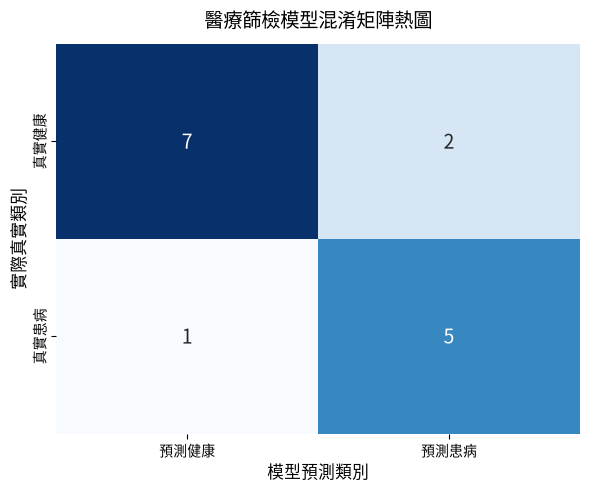

💡 觀念總結：在醫療或詐欺偵測中，『漏報 (FN)』代價極高，必須重點監控召回率 (Recall)！


In [5]:
# 2. 使用 Seaborn 繪製混淆矩陣熱圖
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['預測健康', '預測患病'],
            yticklabels=['真實健康', '真實患病'],
            annot_kws={'size': 14})

plt.title('醫療篩檢模型混淆矩陣熱圖', fontsize=14, pad=12)
plt.xlabel('模型預測類別', fontsize=12)
plt.ylabel('實際真實類別', fontsize=12)
plt.tight_layout()
plt.show()

print("💡 觀念總結：在醫療或詐欺偵測中，『漏報 (FN)』代價極高，必須重點監控召回率 (Recall)！")
